# ۰۱ — کشف: داده، ممیزی زمانی ستون‌ها، فرضیه‌ها و مسیرهای شکست‌خورده

در این نوت‌بوک قبل از ساختن سامانه، داده Olist را از دید **زمان** بررسی می‌کنم. پرسش اصلی:
> هر ستون در چه لحظه‌ای از عمر یک سفارش به وجود می‌آید، و آیا در لحظه تأیید سفارش (لحظه تصمیم) وجود دارد؟

همه داده‌ها را از پایگاه داده می‌خوانم (schemaهای `olist` و `ews`)، هیچ CSV‌ای نمی‌خوانم. فرض این نوت‌بوک این است که `data-factory early-warning` یک بار اجرا شده است.

**بودجه زمانی:** کل چالش نهایی ۸ تا ۱۰ روز کاری. اجرای این نوت‌بوک کمتر از یک دقیقه طول می‌کشد. seed در `factory.toml` است.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from data_factory.config import load_config
from data_factory.db import make_engine
from data_factory import ews_model as em
from data_factory.ews_audit import audit_table, TEMPTING

config = load_config("factory.toml")
SEED = config.ews.seed
np.random.seed(SEED)
engine = make_engine(config.database)
pd.set_option("display.width", 160, "display.max_columns", 20, "display.max_colwidth", 90,
              "display.float_format", "{:.4f}".format)

def q(statement, **params):
    with engine.connect() as connection:
        return pd.read_sql_query(text(statement), connection, params=params)
print("seed", SEED, "| cut-off", config.ews.cutoff.date(), "| evaluation end", config.ews.evaluation_end.date())

seed 42 | cut-off 2018-04-01 | evaluation end 2018-09-01


## ۱. برچسب و واحد پیش‌بینی

- **واحد پیش‌بینی:** یک سفارش.
- **برچسب:** «نظر منفی» یعنی امتیاز ۱ یا ۲.

اول می‌بینم چند سفارش نظر ندارند، چند سفارش چند نظر دارند، و چند سفارش تاریخ تأیید ندارند.

In [2]:
q('''
WITH r AS (SELECT order_id, count(*) n, min(score) mn, max(score) mx FROM olist.order_reviews GROUP BY 1)
SELECT count(*)                                              AS orders,
       count(*) FILTER (WHERE r.order_id IS NULL)            AS without_review,
       count(*) FILTER (WHERE n > 1)                         AS several_reviews,
       count(*) FILTER (WHERE n > 1 AND (mn <= 2) <> (mx <= 2)) AS several_reviews_disagree,
       count(*) FILTER (WHERE o.approved_at IS NULL)         AS without_approval,
       count(*) FILTER (WHERE o.approved_at IS NULL AND o.status = 'delivered') AS without_approval_but_delivered,
       avg((mn <= 2)::int)                                   AS negative_rate
FROM olist.orders o LEFT JOIN r USING (order_id)''').T

,0
orders,99441.0000
without_review,768.0000
several_reviews,547.0000
several_reviews_disagree,96.0000
without_approval,160.0000
without_approval_but_delivered,14.0000
negative_rate,0.1473


تصمیم‌هایی که از این جدول گرفتم:
- **سفارش بی‌نظر:** برچسب ندارد، پس در آموزش و ارزیابی نمی‌آید. ولی در لحظه تأیید هیچ‌کس نمی‌داند مشتری نظر خواهد داد یا نه، پس **در فهرست پیگیری می‌ماند**.
- **عارضه این تصمیم:** اگر بی‌نظرها از نظر رضایت با بقیه فرق داشته باشند، معیار ما فقط روی نظردهنده‌ها معتبر است.
- **چند نظر برای یک سفارش:** سفارش منفی است اگر حداقل یکی از نظرها منفی باشد.
- **بی‌تأیید:** لحظه تصمیم = زمان خرید، که زودترین لحظه وجود سفارش است، به‌اضافه یک پرچم.

## ۲. نرخ نظر منفی در طول زمان

قبل از انتخاب تاریخ مرز، باید ببینم داده در زمان چطور رفتار می‌کند.

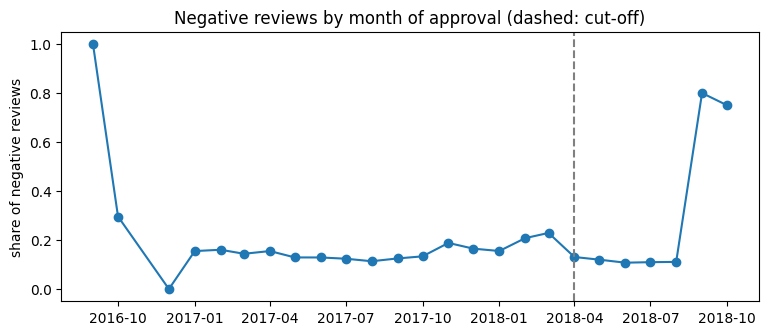

,month,orders,negative_rate,days_until_label
13,2017-11-01,7340,0.1881,16.9816
14,2017-12-01,5778,0.1648,18.3460
15,2018-01-01,7120,0.1552,16.8621
16,2018-02-01,6653,0.2077,18.6006
17,2018-03-01,7228,0.2290,17.6823
18,2018-04-01,6726,0.1307,13.9418
19,2018-05-01,7029,0.1198,14.1357
20,2018-06-01,6139,0.1075,12.2349
21,2018-07-01,6131,0.1096,11.4249
22,2018-08-01,6646,0.1107,9.9125


In [3]:
monthly = q('''
SELECT date_trunc('month', f.decision_at)::date AS month, count(*) AS orders,
       avg(f.label_negative::int) AS negative_rate,
       avg(EXTRACT(epoch FROM f.label_known_at - f.decision_at) / 86400) AS days_until_label
FROM ews.order_features f WHERE f.label_negative IS NOT NULL
GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(pd.to_datetime(monthly.month), monthly.negative_rate, marker="o")
ax.axvline(config.ews.cutoff, color="grey", linestyle="--")
ax.set_ylabel("share of negative reviews"); ax.set_title("Negative reviews by month of approval (dashed: cut-off)")
plt.show()
monthly.tail(12)

از نمودار می‌بینم:
- نرخ نظر منفی ثابت نیست. در نوامبر ۲۰۱۷ (بلک‌فرایدی) و فوریه تا مارس ۲۰۱۸ بالا می‌رود و از آوریل ۲۰۱۸ برمی‌گردد.
- **برچسب دیر می‌رسد:** معمولاً چند هفته بعد از تأیید، چون مشتری بعد از تحویل نظر می‌دهد.

**انتخاب مرز:** ۱ آوریل ۲۰۱۸.
- پنج ماه (آوریل تا اوت) برای ارزیابی می‌ماند، که هم «ماه‌های مختلف دوره ارزیابی» را می‌دهد و هم «آخرین ماه» (اوت) را.
- آموزش با دوره شلوغ و پرمشکل فوریه و مارس تمام می‌شود. این یک جابه‌جایی واقعی است که در ارزیابی دیده می‌شود.

## ۳. بلوغ برچسب: نشت زمانی در خود برچسب

در روز مرز، برچسب سفارش‌هایی که اواخر مارس تأیید شده‌اند **هنوز معلوم نبود**. اگر آن‌ها را با برچسب نهایی در آموزش بیاورم، از آینده استفاده کرده‌ام. برای همین در آموزش فقط سفارش‌هایی را نگه می‌دارم که نظرشان **قبل از مرز** پاسخ داده شده بود.

In [4]:
features = q("SELECT * FROM ews.order_features ORDER BY order_id")
features = em.prepare_types(features)
split = em.temporal_split(features, config.ews.cutoff, config.ews.evaluation_end)
pd.Series(split.counts)

orders                              99441.0000
no_review                             768.0000
before_cutoff_labelled              65983.0000
dropped_label_not_known_at_cutoff    4071.0000
train                               61912.0000
test                                32671.0000
after_end                              20.0000
train_negative_rate                     0.1542
test_negative_rate                      0.1160
dtype: float64

## ۴. ممیزی زمانی: هر ستون کی به وجود می‌آید؟

برای ستون‌هایی که مطمئن نیستم، شاهد عددی جمع می‌کنم.

**الف) تاریخ ثبت نظر در برابر پاسخ نظر.** `review_creation_date` روزی است که نظرسنجی فرستاده شده؛ امتیاز وقتی معلوم می‌شود که مشتری **پاسخ داده** است (`review_answer_timestamp`). پس سابقه نظرهای فروشنده را با زمان پاسخ می‌شمارم، نه زمان ایجاد.

In [5]:
q('''
SELECT percentile_cont(ARRAY[0.5, 0.9, 0.99]) WITHIN GROUP (ORDER BY EXTRACT(epoch FROM r.answered_at - r.created_at) / 86400)
         AS days_created_to_answered,
       avg((r.created_at::date >= o.delivered_customer_at::date)::int) AS survey_on_or_after_delivery,
       avg((r.answered_at > o.approved_at)::int)                       AS answered_after_approval
FROM olist.order_reviews r JOIN olist.orders o USING (order_id)
WHERE o.delivered_customer_at IS NOT NULL''').T

,0
days_created_to_answered,"[1.681886574074074, 4.856131944444444, 21.895774305555463]"
survey_on_or_after_delivery,0.9468
answered_after_approval,0.9998


**ب) مهلت ارسال فروشنده (`shipping_limit_date`).** اگر این ستون در لحظه تأیید از روی تأیید محاسبه شده باشد، فاصله‌اش تا تأیید باید چند مقدار ثابت باشد. اگر بعداً به‌روزرسانی شده بود، به تاریخ تحویل به حمل‌کننده نزدیک می‌شد.

In [6]:
q('''
SELECT round(EXTRACT(epoch FROM i.shipping_limit_at - o.approved_at) / 86400) AS days_after_approval, count(*) AS items
FROM olist.order_items i JOIN olist.orders o USING (order_id)
WHERE o.approved_at IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 6''')

,days_after_approval,items
0,6.0000,44724
1,4.0000,19293
2,5.0000,11651
3,7.0000,9920
4,2.0000,5893
5,8.0000,4777


بیشتر ردیف‌ها روی چند فاصله ثابت از تأیید هستند (مهلت آماده‌سازی فروشنده). پس این ستون **در لحظه تأیید** تعیین می‌شود و مجاز است.

**ج) وضعیت سفارش (`status`)** فقط «آخرین وضعیت» است. سفارشی که امروز تأیید شده، در لحظه تصمیم وضعیتش `approved` است، نه `delivered` یا `canceled`. پس این ستون از آینده خبر می‌دهد:

In [7]:
q('''
SELECT o.status, count(*) AS orders, avg((r.score <= 2)::int) AS negative_rate
FROM olist.orders o JOIN (SELECT order_id, min(score) score FROM olist.order_reviews GROUP BY 1) r USING (order_id)
GROUP BY 1 ORDER BY 2 DESC''')

,status,orders,negative_rate
0,delivered,95832,0.1285
1,shipped,1032,0.6967
2,canceled,605,0.7686
3,unavailable,595,0.8487
4,invoiced,309,0.8285
5,processing,295,0.9288
6,created,3,0.6667
7,approved,2,0.5000


نرخ نظر منفی سفارش‌های `canceled` و `unavailable` چند برابر بقیه است. ستونی که این را بداند، مدل را «درخشان» می‌کند، ولی در لحظه تأیید هنوز وجود ندارد.

### جدول کامل ممیزی زمانی

این جدول از `src/data_factory/ews_audit.py` می‌آید و مدل فهرست ویژگی‌هایش را **فقط** از همین جدول می‌گیرد. یک تست، ستون‌های view پایگاه داده را با این جدول مقایسه می‌کند: ستونی که در جدول نباشد، به مدل نمی‌رسد.

In [8]:
audit = audit_table()
print("columns:", len(audit), "| used by the model:", int(audit.used_by_model.sum()),
      "| tempting, left out:", len(TEMPTING))
audit

columns: 45 | used by the model: 36 | tempting, left out: 5


,column,moment,available_at_approval,certainty,used_by_model
0,order_id,purchase,True,primary key,False
1,decision_at,approval,True,the decision moment itself (purchase time when approval is missing),False
2,label_negative,review,False,the target: score of the review answered after delivery,False
3,label_known_at,review,False,when the label became known; used only for label maturity,False
4,approval_missing,approval,True,approved_at is null at the decision moment,True
5,approval_hours,approval,True,"purchase -> approval, both before or at the decision",True
6,purchase_hour,purchase,True,order_purchase_timestamp,True
7,purchase_weekday,purchase,True,order_purchase_timestamp,True
8,promised_days,purchase,True,estimated delivery date is shown to the customer at checkout (Olist data description);...,True
9,days_to_ship_limit,approval,True,seller shipping limit is set from the approval (exploration: limit - approval is a fix...,True


### سه (و بیشتر) ستون وسوسه‌کننده که کنار گذاشتم

| ستون | چرا وسوسه‌کننده است | چرا کنار گذاشتم |
|---|---|---|
| `status` نهایی | لغو و ناموجود بودن قوی‌ترین نشانه نارضایتی است | آخرین وضعیت است و در لحظه تأیید هنوز `approved` است |
| روزهای تأخیر تحویل / مدت تحویل | تأخیر دلیل اصلی نظر منفی است | به `delivered_customer_at` نیاز دارد که هفته‌ها بعد پر می‌شود |
| پرچم‌های ساخته‌شده `orders` (مثلاً `flag_status_delivery_mismatch`) | در مرحله ۲ برای کیفیت داده ساختم | از وضعیت نهایی و تاریخ تحویل ساخته شده‌اند |
| نرخ نظر منفی فروشنده روی **همه** داده | ساده‌ترین «سابقه فروشنده» | نظرهای آینده و حتی نظر خود همین سفارش را می‌شمارد |

در نوت‌بوک ۰۲، «مدل تقلبی» را با همین ستون‌ها می‌سازم و فاصله‌اش با مدل واقعی را اندازه می‌گیرم.

In [9]:
naive = q('''
WITH s AS (SELECT i.seller_id, avg(l.negative::int) rate_all_time, count(*) n
           FROM olist.order_items i JOIN ews.order_labels l USING (order_id) GROUP BY 1)
SELECT corr(f.seller_prior_negative_rate, f.label_negative::int) AS honest_history_corr,
       corr(s.rate_all_time, f.label_negative::int)             AS naive_all_time_corr
FROM ews.order_features f
JOIN (SELECT DISTINCT ON (order_id) order_id, seller_id FROM olist.order_items ORDER BY order_id, order_item_id) m USING (order_id)
JOIN s USING (seller_id)
WHERE f.label_negative IS NOT NULL''')
naive

,honest_history_corr,naive_all_time_corr
0,0.0737,0.2528


همبستگی نسخه ساده‌انگارانه سابقه فروشنده با برچسب، بیشتر از نسخه درست زمانی است. دلیلش این است که نسخه ساده نظر خود همین سفارش را هم می‌شمارد. این همان خطری است که بریف درباره ویژگی‌های تجمیعی گفته بود.

## ۵. فرضیه منبع بیرونی: تعطیلات در پنجره تحویل

**فرضیه:** وقتی فاصله تأیید تا موعد تحویل تعطیلات رسمی دارد، روزهای کاری کمتری برای رساندن سفارش می‌ماند، پس تأخیر و نظر منفی بیشتر می‌شود.

**چرا مجاز است:** تقویم تعطیلات سال‌ها از قبل اعلام می‌شود، پس در لحظه تأیید معلوم است.

**منبع:** BrasilAPI (`/api/feriados/v1/<year>`)، رایگان، بدون کلید، و از ایران در دسترس (پاسخ ۲۰۰ در کمتر از یک ثانیه). Nager.Date جایگزین ثبت‌شده آن است.

In [10]:
labelled = features[features.label_negative.notna()].copy()
labelled["holiday_in_window"] = np.where(labelled.holidays_in_window > 0, "yes", "no")
labelled["month"] = labelled.decision_at.dt.month
by_holiday = labelled.groupby("holiday_in_window").agg(orders=("order_id", "size"),
                                                       negative_rate=("label_negative", lambda s: s.astype(float).mean()),
                                                       promised_days=("promised_days", "median"))
within_month = (labelled.groupby(["month", "holiday_in_window"])["label_negative"]
                .apply(lambda s: s.astype(float).mean()).unstack().dropna())
within_month["difference"] = within_month["yes"] - within_month["no"]
display(by_holiday)
print("months where 'holiday in window' has a higher negative rate:",
      int((within_month.difference > 0).sum()), "of", len(within_month))
within_month

,orders,negative_rate,promised_days
holiday_in_window,,,
no,50623,0.1402,21.0000
yes,48050,0.1547,26.0000


months where 'holiday in window' has a higher negative rate: 8 of 12


holiday_in_window,no,yes,difference
month,,,
1,0.1397,0.1707,0.0310
2,0.2314,0.1679,-0.0634
3,0.1921,0.2153,0.0232
4,0.1180,0.1383,0.0203
5,0.1177,0.1287,0.0110
6,0.1118,0.1292,0.0174
7,0.1148,0.1905,0.0757
8,0.1137,0.1074,-0.0062
9,0.1315,0.1239,-0.0076


نرخ نظر منفی سفارش‌هایی که در پنجره تحویلشان تعطیلی هست، کمی بالاتر است (0.1547 در برابر 0.1402)، و در ۸ ماه از ۱۲ ماه هم جهت همین است. ولی همین سفارش‌ها وعده تحویل طولانی‌تری هم دارند (میانه ۲۶ روز در برابر ۲۱ روز). پس معلوم نیست اثر از خود تعطیلات است یا از طولانی بودن پنجره، که `promised_days` آن را جداگانه به مدل می‌دهد. اثر واقعی این سیگنال را در نوت‌بوک ۰۲ با مدل و بدون آن می‌سنجم. اگر چیزی اضافه نکند، این نتیجه منفی را هم گزارش می‌کنم.

## ۶. مسیرهایی که شکست خوردند

1. **مدل تقلبی:** با ستون‌های آینده عددی خیره‌کننده می‌گیرد (نوت‌بوک ۰۲). این را عمداً ساختم تا هزینه نشت را بسنجم.
2. **تنظیم ابرپارامتر HGB:** سه تنظیم مختلف (عمق، تعداد برگ، حداقل نمونه برگ) را روی **اعتبارسنجی زمانی داخل دوره آموزش** امتحان کردم. همه حدود ۲۱ تا ۲۲ درصد شکار داشتند و فرقشان در حد نوسان بود. پس ساده‌ترین را نگه داشتم. (در همان آزمایش، عدد مجموعه ارزیابی را هم دیدم. این را صادقانه می‌گویم. تصمیم نهایی را فقط با اعتبارسنجی زمانی می‌گیرم.)
3. **«قاعده ساده» بر اساس سابقه بد فروشنده** کمتر از «تعداد اقلام سفارش» شکار کرد. شهود اولیه من غلط بود.
4. **باران (Open-Meteo)** را هم بررسی کردم، ولی فقط باران روزهای *قبل* از تأیید مجاز است. باران آینده نشت است، و پیش‌بینی هوای سال ۲۰۱۷ در دسترس نیست. فرضیه ضعیف بود و کنار گذاشتم.

In [11]:
engine.dispose()